<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/AyeshaZahid_ComplexTask2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question No 1: Part (a) **

Saving apples.jpg to apples (4).jpg


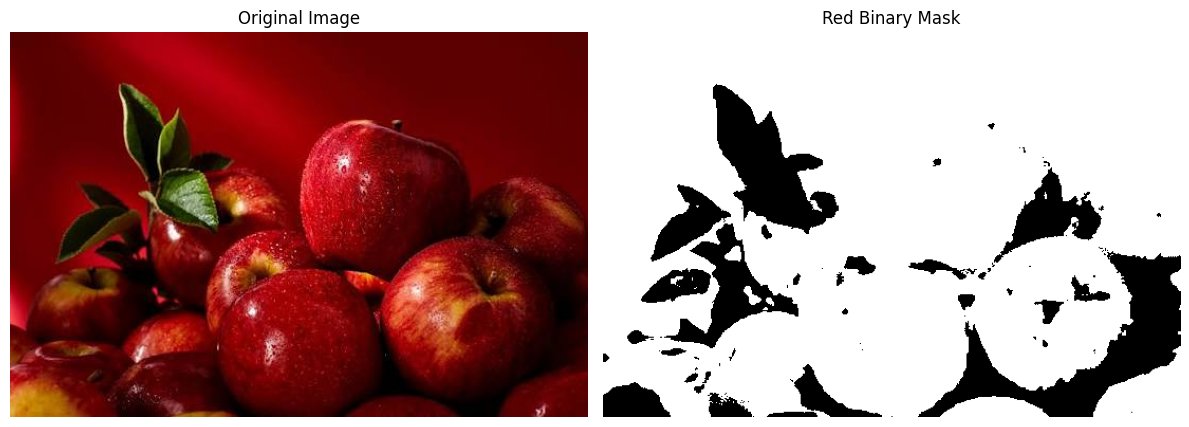

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Upload the image file
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
img = cv2.imread(file_name)

    # Convert BGR  to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. Convert to HSV color space
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # 3. Define mask thresholds for red color
    # Red wraps around both the low end (0-10) and high end (170-180) of the Hue spectrum
lower_red1 = np.array([0, 50, 50])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([170, 50, 50])
upper_red2 = np.array([180, 255, 255])

    # Generate masks for both ranges
mask1 = cv2.inRange(img_hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(img_hsv, lower_red2, upper_red2)

    # Combine both masks to get the final red mask
red_mask = cv2.bitwise_or(mask1, mask2)

    # 4. Display the results
plt.figure(figsize=(12, 6))

    # Show Original Image
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('off')

    # Show Binary Mask
plt.subplot(1, 2, 2)
plt.imshow(red_mask, cmap='gray')
plt.title('Red Binary Mask')
plt.axis('off')

plt.tight_layout()
plt.show()


**Part b:**

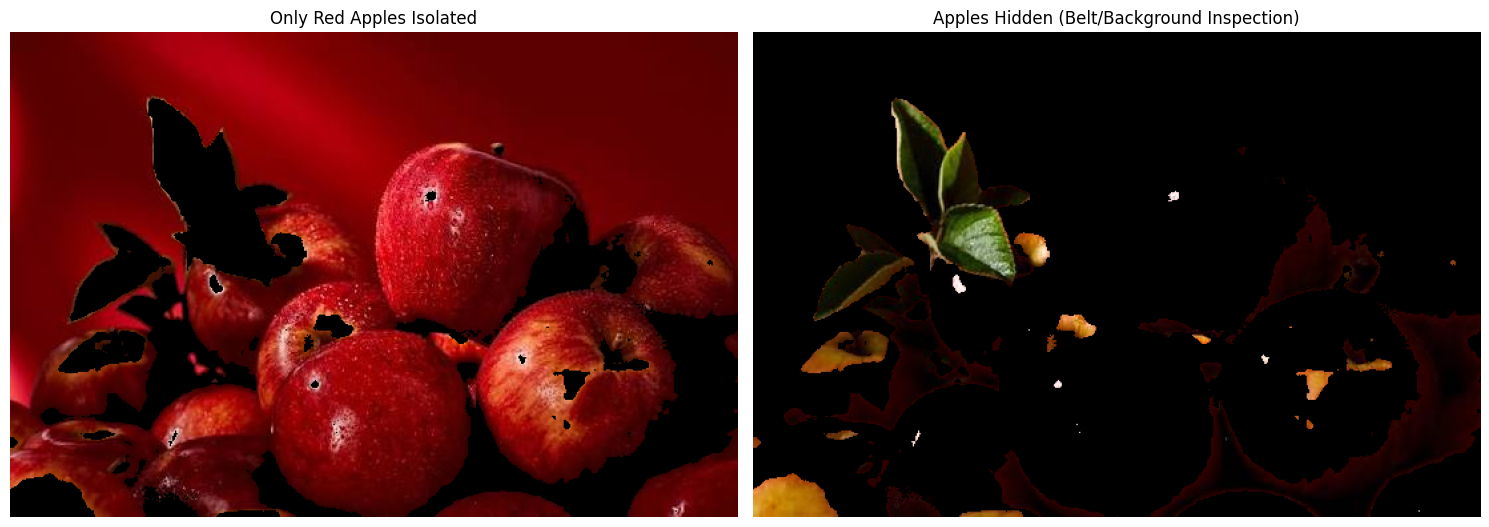

In [17]:
import cv2
import matplotlib.pyplot as plt
# 1.  binary mask to the original RGB image
apples_only = cv2.bitwise_and(img_rgb, img_rgb, mask=red_mask)

# 2. Image with red apples hidden
mask_inverse = cv2.bitwise_not(red_mask)
apples_hidden = cv2.bitwise_and(img_rgb, img_rgb, mask=mask_inverse)

# 3. Display both results side-by-side
plt.figure(figsize=(15, 7))

# Show only the red apples
plt.subplot(1, 2, 1)
plt.imshow(apples_only)
plt.title('Only Red Apples Isolated')
plt.axis('off')

# Show background/belt with apples hidden
plt.subplot(1, 2, 2)
plt.imshow(apples_hidden)
plt.title('Apples Hidden (Belt/Background Inspection)')
plt.axis('off')

plt.tight_layout()
plt.show()

**Part C:**

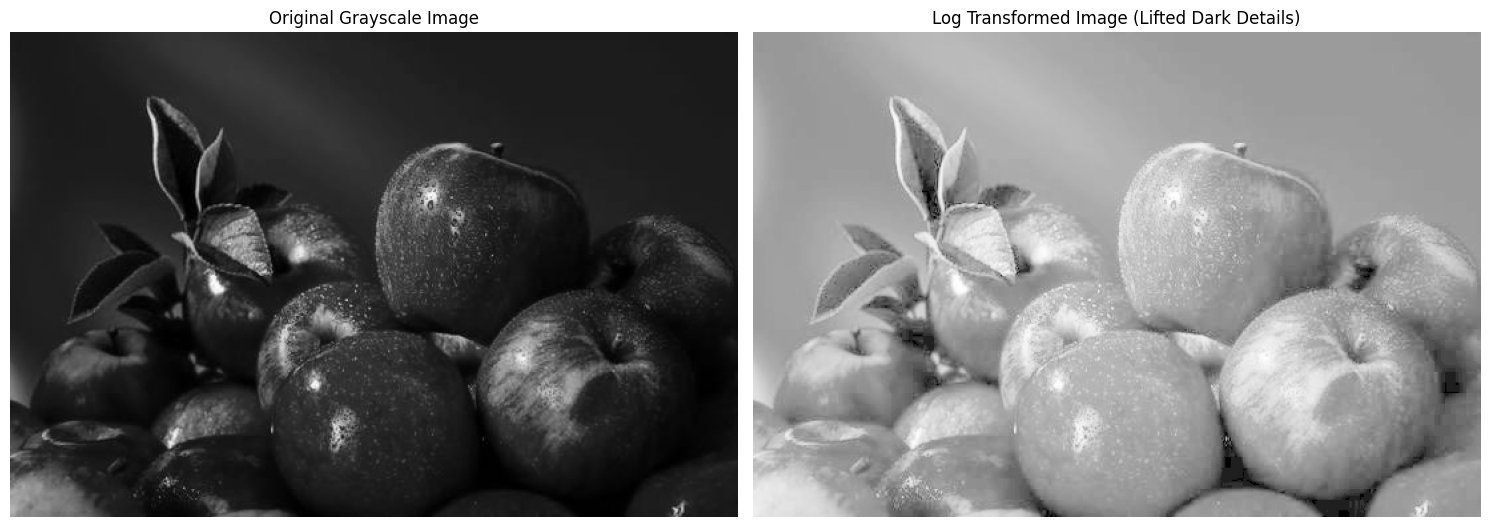

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. RGB to grayscale
gray_img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# 2. Log Transformation
c = 255 / np.log(1 + np.max(gray_img))
log_img = c * (np.log(1 + gray_img.astype(np.float64)))
# Convert the result back to uint8
log_img = np.array(log_img, dtype=np.uint8)
plt.figure(figsize=(15, 7))
# Show Grayscale Image
plt.subplot(1, 2, 1)
plt.imshow(gray_img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')
# Show Log-Transformed Image
plt.subplot(1, 2, 2)
plt.imshow(log_img, cmap='gray')
plt.title('Log Transformed Image (Lifted Dark Details)')
plt.axis('off')
plt.tight_layout()
plt.show()

**Part D:**

Grayscale value at [100, 100] BEFORE gamma correction: 29
Grayscale value at [100, 100] AFTER gamma correction: 106


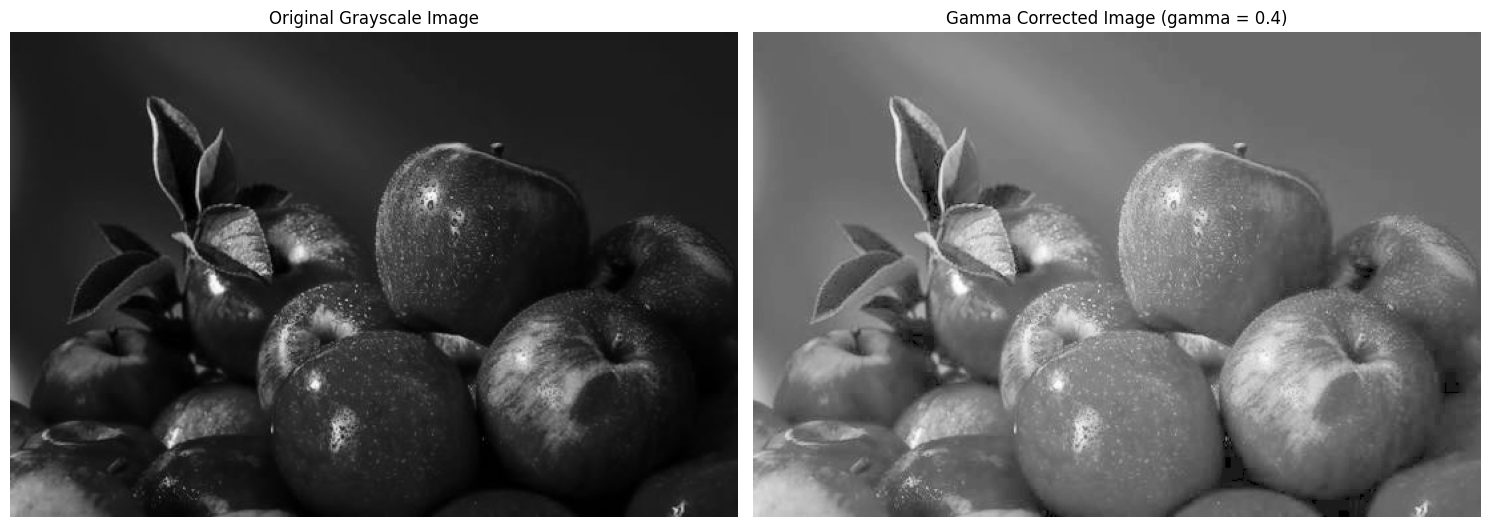

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Apply Gamma Correction with gamma = 0.4
gamma = 0.4
lookup_table = np.array([((i / 255.0) ** gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
gamma_corrected_img = cv2.LUT(gray_img, lookup_table)

pixel_val_before = gray_img[100, 100]
pixel_val_after = gamma_corrected_img[100, 100]

# Print the comparison values
print(f"Grayscale value at [100, 100] BEFORE gamma correction: {pixel_val_before}")
print(f"Grayscale value at [100, 100] AFTER gamma correction: {pixel_val_after}")

#  Display the images
plt.figure(figsize=(15, 7))

# Original Grayscale
plt.subplot(1, 2, 1)
plt.imshow(gray_img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

# Gamma Corrected
plt.subplot(1, 2, 2)
plt.imshow(gamma_corrected_img, cmap='gray')
plt.title('Gamma Corrected Image (gamma = 0.4)')
plt.axis('off')

plt.tight_layout()
plt.show()